# 🚲 Parquet contra CSV con los viajes de Ecobici en R

Parquet es un formato que guarda los datos por columnas, comprimidos y con su tipo. En esta notebook lo comparamos con el CSV usando un archivo real y grande: los más de 3 millones de viajes en Ecobici de 2025, que publica la Ciudad de Buenos Aires en [Buenos Aires Data](https://data.buenosaires.gob.ar/dataset/bicicletas-publicas). Es la versión en R de la [notebook de Python](https://colab.research.google.com/github/jumafernandez/modelado-gestion-datos-untref/blob/main/codigo/python_parquet_vs_csv.ipynb).

Medimos cuatro cosas:

1. Cuánto pesa cada archivo.
2. Cuánto tarda en cargarse completo.
3. Cuánto tarda en leer solo dos columnas.
4. Cuánto tarda DuckDB en responder una consulta sobre cada uno.

> Los tiempos dependen de la máquina de Colab que toque en cada sesión. Lo que importa es la diferencia entre los dos formatos.

## 📦 Los paquetes

Usamos `readr` para el CSV, `arrow` para Parquet y `duckdb` para las consultas. `arrow` y `duckdb` no vienen instalados en Colab: los instalamos desde el repositorio de Posit, que los tiene ya compilados para Linux, así la instalación tarda segundos.

In [1]:
# Repositorio de Posit con los paquetes ya compilados para la versión de Linux de Colab
ubuntu <- system("lsb_release -cs", intern = TRUE)
options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", ubuntu, "/latest")))
# El repositorio reconoce la versión de R por esta "firma" de los pedidos
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(), paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))

install.packages(c("arrow", "duckdb"))

library(readr)
library(dplyr)
library(arrow)
library(DBI)
library(duckdb)
library(ggplot2)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp




## 📥 Los datos

Bajamos el archivo de 2025: un ZIP de unos 200 MB que adentro tiene un CSV de más de 800 MB. Para que la descarga sea más rápida usamos `aria2c`, que baja el archivo en varias partes a la vez.

In [2]:
system("apt-get install -y -qq aria2 > /dev/null")
system("aria2c -x 16 -s 16 -q --allow-overwrite=true -o recorridos-2025.zip https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/bicicletas-publicas/recorridos-realizados-2025.zip")
unzip("recorridos-2025.zip")

cat("Trips.csv:", round(file.size("Trips.csv") / 1e6), "MB\n")

Trips.csv: 832 MB


## 📄 Leer el CSV

Leemos el CSV con `readr` y medimos cuánto tarda.

In [3]:
inicio <- Sys.time()
viajes <- read_csv("Trips.csv", show_col_types = FALSE)
carga_csv <- as.numeric(Sys.time() - inicio, units = "secs")

cat(format(nrow(viajes), big.mark = ".", decimal.mark = ","), "viajes leídos en", round(carga_csv, 1), "segundos\n")
head(viajes)

3.156.182 viajes leídos en 27.1 segundos


Id_recorrido,duracion_recorrido,fecha_origen_recorrido,id_estacion_origen,nombre_estacion_origen,direccion_estacion_origen,long_estacion_origen,lat_estacion_origen,fecha_destino_recorrido,id_estacion_destino,nombre_estacion_destino,direccion_estacion_destino,long_estacion_destino,lat_estacion_destino,id_usuario,modelo_bicicleta,género
<chr>,<dbl>,<dttm>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
27699090BAEcobici,800,2025-10-15 11:12:52,146BAEcobici,146 - Hospital Francés,"3024 Calvo, Carlos",-58.40784,-34.62211,2025-10-15 11:26:12,17BAEcobici,017 - Plaza Almagro,"441 Bulnes & Peron, Juan Domingo, Tte. General",-58.41873,-34.60641,1177390BAEcobici,ICONIC,FEMALE
24622664BAEcobici,571,2025-01-10 08:48:58,70BAEcobici,070 - ARAOZ,1413 Araoz & Gorriti CABA,-58.42606,-34.59269,2025-01-10 08:58:29,74BAEcobici,074 - INSTITUTO LELOIR,Juana De Ibarbourou & Av Patricias Argentinas,-58.43454,-34.60439,357363BAEcobici,ICONIC,OTHER
24621373BAEcobici,348,2025-01-10 07:11:15,135BAEcobici,135 - MARCELO T. DE ALVEAR,Esmeralda & Paraguay,-58.37836,-34.59764,2025-01-10 07:17:03,130BAEcobici,130 - RETIRO II,Av. Dr. José María Ramos Mejía 1350,-58.37436,-34.59174,693254BAEcobici,ICONIC,MALE
27815450BAEcobici,343,2025-10-23 09:03:21,471BAEcobici,173 - EL LIBERTADOR,Av. San Martín 6220,-58.50331,-34.59473,2025-10-23 09:09:04,241BAEcobici,348 - Villa del Parque,"Gutierrez, Ricardo 3105",-58.49412,-34.60087,459726BAEcobici,ICONIC,MALE
28272276BAEcobici,931,2025-11-26 00:25:37,466BAEcobici,333 - PARQUE DE LA ESTACIÓN,Dr. Tomás Manuel de Anchorena 170,-58.41184,-34.60810,2025-11-26 00:41:08,527BAEcobici,068 - AV. CORDOBA,Av. Cordoba 5403,-58.43839,-34.58873,1153980BAEcobici,ICONIC,MALE
27851138BAEcobici,3108,2025-10-26 17:40:10,222BAEcobici,160 - Godoy Cruz y Libertador,Av. Cerviño 4301,-58.41854,-34.57592,2025-10-26 18:31:58,516BAEcobici,368 - PLAZA DE LA SHOÁ,Av. Del Libertador 3899,-58.42335,-34.57100,1427741BAEcobici,ICONIC,MALE


### Los tipos se adivinan

Un CSV es texto: no guarda qué tipo de dato tiene cada columna, y `readr` lo tiene que adivinar mirando las primeras filas. Esta vez acierta: reconoce las fechas y entiende que `1,016` es un número con coma como separador de miles (en los datos, las duraciones de 1.000 segundos o más vienen escritas así). Pero sigue siendo una adivinanza: depende de las primeras filas y de la configuración regional. En un CSV argentino, por ejemplo, la coma sería el separador de decimales. En la notebook de Python, pandas no lo adivina y la duración queda como texto.

In [4]:
sapply(viajes[c("duracion_recorrido", "fecha_origen_recorrido")], class)

$duracion_recorrido
[1] "numeric"

$fecha_origen_recorrido
[1] "POSIXct" "POSIXt"

Guardamos la tabla en Parquet. Parquet no adivina: guarda el tipo de cada columna, y al leerlo de nuevo los tipos vuelven tal cual.

In [5]:
write_parquet(viajes, "viajes.parquet")

sapply(read_parquet("viajes.parquet", col_select = c("duracion_recorrido", "fecha_origen_recorrido")), class)

$duracion_recorrido
[1] "numeric"

$fecha_origen_recorrido
[1] "POSIXct" "POSIXt"

## ⚖️ La comparación

### 1. El tamaño

Parquet comprime cada columna por separado, y una columna tiene datos muy parecidos entre sí, como la misma estación o el mismo modelo de bicicleta repetidos muchas veces. Por eso comprime mucho mejor que el texto del CSV.

In [6]:
tamanio_csv <- file.size("Trips.csv") / 1e6
tamanio_parquet <- file.size("viajes.parquet") / 1e6

cat("CSV:", round(tamanio_csv), "MB\n")
cat("Parquet:", round(tamanio_parquet), "MB\n")

CSV: 832 MB
Parquet: 138 MB


### 2. Cargar todo

Ya medimos cuánto tarda el CSV. Ahora, el Parquet.

In [7]:
inicio <- Sys.time()
completo <- read_parquet("viajes.parquet")
carga_parquet <- as.numeric(Sys.time() - inicio, units = "secs")

cat("CSV:", round(carga_csv, 1), "segundos\n")
cat("Parquet:", round(carga_parquet, 1), "segundos\n")

CSV: 27.1 segundos
Parquet: 1.7 segundos


### 3. Leer solo dos columnas

Muchas veces no hacen falta todas las columnas. El CSV guarda los datos fila por fila, así que para sacar dos columnas igual tiene que recorrer el archivo completo. Parquet los guarda columna por columna y lee solo las que se le piden.

In [8]:
COLUMNAS <- c("fecha_origen_recorrido", "género")

inicio <- Sys.time()
dos_csv <- read_csv("Trips.csv", col_select = all_of(COLUMNAS), show_col_types = FALSE)
columnas_csv <- as.numeric(Sys.time() - inicio, units = "secs")

inicio <- Sys.time()
dos_parquet <- read_parquet("viajes.parquet", col_select = all_of(COLUMNAS))
columnas_parquet <- as.numeric(Sys.time() - inicio, units = "secs")

cat("CSV:", round(columnas_csv, 1), "segundos\n")
cat("Parquet:", round(columnas_parquet, 2), "segundos\n")

CSV: 5.9 segundos
Parquet: 0.32 segundos


### 4. Una consulta con DuckDB

DuckDB consulta los archivos directamente, sin cargarlos antes en R. Contamos los viajes de cada hora del día, primero sobre el CSV y después sobre el Parquet.

In [9]:
con <- suppressMessages(dbConnect(duckdb()))

viajes_por_hora <- function(archivo) {
  dbGetQuery(con, paste0("
    SELECT hour(fecha_origen_recorrido) AS hora, COUNT(*) AS viajes
    FROM '", archivo, "'
    GROUP BY hora
    ORDER BY hora"))
}

inicio <- Sys.time()
resultado_csv <- viajes_por_hora("Trips.csv")
consulta_csv <- as.numeric(Sys.time() - inicio, units = "secs")

inicio <- Sys.time()
por_hora <- viajes_por_hora("viajes.parquet")
consulta_parquet <- as.numeric(Sys.time() - inicio, units = "secs")

cat("CSV:", round(consulta_csv, 2), "segundos\n")
cat("Parquet:", round(consulta_parquet, 2), "segundos\n")

CSV: 3.97 segundos
Parquet: 0.98 segundos


## 📊 Los resultados

Las cuatro comparaciones juntas. Arriba de cada gráfico, cuántas veces mejor le fue a Parquet.

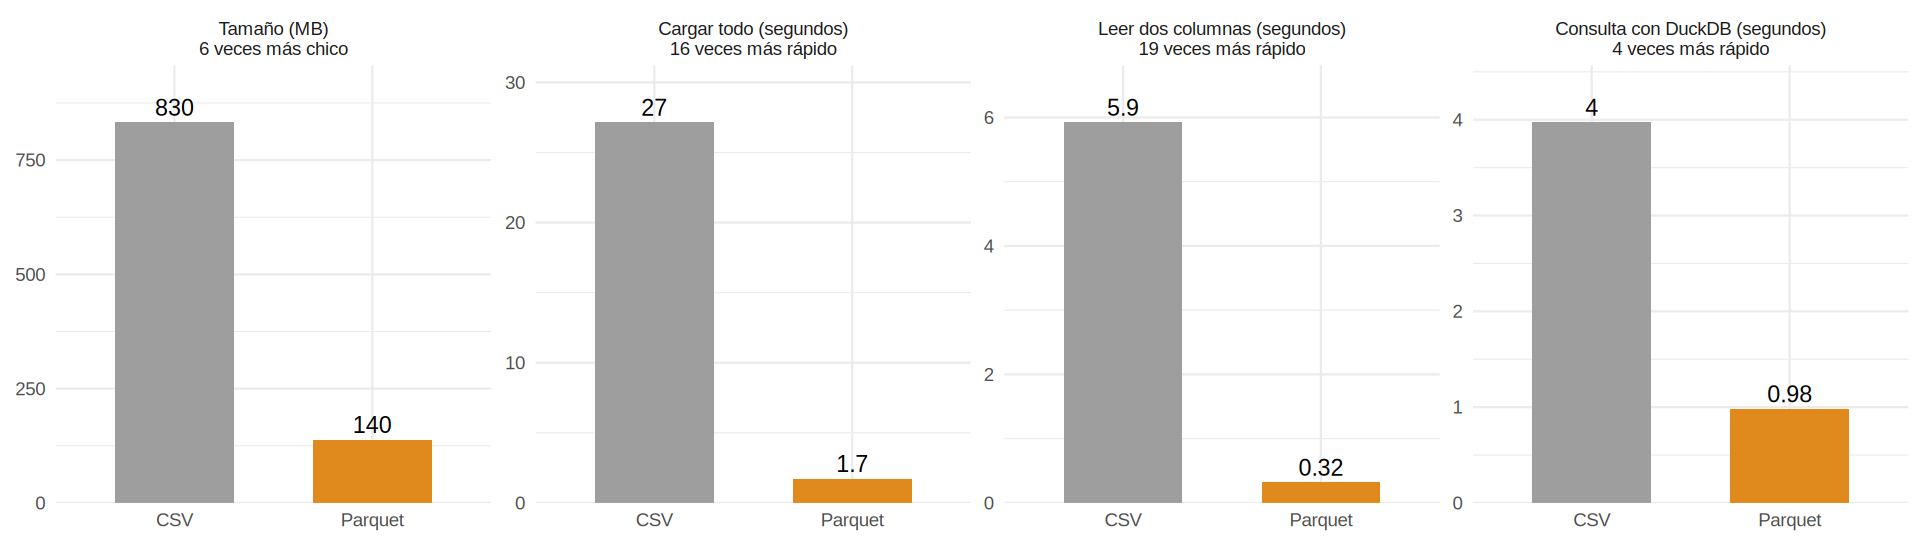

In [10]:
comparaciones <- c("Tamaño (MB)", "Cargar todo (segundos)", "Leer dos columnas (segundos)", "Consulta con DuckDB (segundos)")
valores_csv <- c(tamanio_csv, carga_csv, columnas_csv, consulta_csv)
valores_parquet <- c(tamanio_parquet, carga_parquet, columnas_parquet, consulta_parquet)
mejor <- c("más chico", "más rápido", "más rápido", "más rápido")

titulos <- paste0(comparaciones, "\n", round(valores_csv / valores_parquet), " veces ", mejor)

resultados <- data.frame(
  titulo = factor(rep(titulos, each = 2), levels = titulos),
  formato = rep(c("CSV", "Parquet"), times = 4),
  valor = as.vector(rbind(valores_csv, valores_parquet))
)

options(repr.plot.width = 16, repr.plot.height = 4.5)

ggplot(resultados, aes(x = formato, y = valor, fill = formato)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = signif(valor, 2)), vjust = -0.4) +
  facet_wrap(~ titulo, scales = "free_y", nrow = 1) +
  scale_fill_manual(values = c(CSV = "#9e9e9e", Parquet = "#e08a1e")) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 14) +
  theme(legend.position = "none")

## 🕐 Y de paso, ¿a qué hora se usa Ecobici?

El resultado de la consulta de DuckDB, en un gráfico.

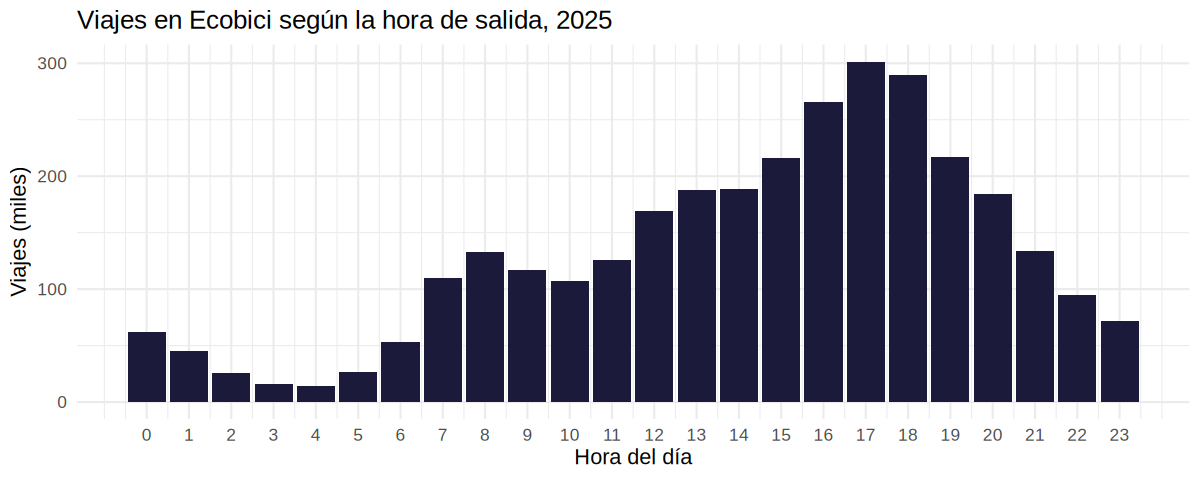

In [11]:
options(repr.plot.width = 10, repr.plot.height = 4)

ggplot(por_hora, aes(x = hora, y = viajes / 1000)) +
  geom_col(fill = "#1c1a3a") +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "Viajes en Ecobici según la hora de salida, 2025", x = "Hora del día", y = "Viajes (miles)") +
  theme_minimal(base_size = 13)

## 🧾 Para llevarse

- Parquet ocupa varias veces menos que el CSV y conserva el tipo de cada columna.
- Para cargar todo, Parquet es más rápido. `readr` es un lector de CSV muy rápido, pero cualquier lector de CSV tiene que leer el texto completo.
- La diferencia más grande aparece al leer pocas columnas: Parquet lee solo esas, y el CSV tiene que recorrer todo el archivo.
- DuckDB consulta los dos formatos sin cargarlos en memoria, y sobre Parquet responde mucho más rápido.

Por eso Parquet es el formato de los data lakes y de los lakehouses: los datos quedan en archivos abiertos que cualquier herramienta puede leer, y se consultan rápido.